### MAKE MOONS PROJECT

###1. Dataset Generation and Preprocessing

---
---

We generate the 2D `make_moons` dataset and split it into training and testing sets.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import torch
import torch.nn as nn
import torch.optim as optim

# Generate dataset
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to PyTorch Tensors
X_train_t = torch.FloatTensor(X_train)
y_train_t = torch.LongTensor(y_train)
X_test_t = torch.FloatTensor(X_test)
y_test_t = torch.LongTensor(y_test)

### 2. 2-Layer ANN Model Definition
We define a simple network with one hidden layer, utilizing ReLU activation and a Softmax output layer (represented via CrossEntropyLoss which implicitly handles softmax stably during training, while we apply explicit softmax for predictions).

In [11]:
class SimpleANN(nn.Module):
    def __init__(self):
        super(SimpleANN, self).__init__()
        # 2-layer network (Input -> Hidden -> Output)
        self.hidden = nn.Linear(2, 16)
        self.relu = nn.ReLU()
        self.output = nn.Linear(16, 2)
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.relu(self.hidden(x))
        x = self.output(x)
        return self.softmax(x)  # Explicitly using softmax as requested

model = SimpleANN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.03)

### 3. Model Training
We train the neural network for 200 epochs, tracking train/test loss and accuracy.

In [12]:
epochs = 200
train_losses, test_losses = [], []
train_accs, test_accs = [], []

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    # Forward pass
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)

    # Backward pass
    loss.backward()
    optimizer.step()

    # Track Train Metrics
    _, predicted_train = torch.max(outputs, 1)
    train_acc = (predicted_train == y_train_t).sum().item() / y_train_t.size(0)

    # Track Test Metrics
    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_t)
        test_loss = criterion(test_outputs, y_test_t)
        _, predicted_test = torch.max(test_outputs, 1)
        test_acc = (predicted_test == y_test_t).sum().item() / y_test_t.size(0)

    train_losses.append(loss.item())
    test_losses.append(test_loss.item())
    train_accs.append(train_acc)
    test_accs.append(test_acc)

print("Training Complete!")

Training Complete!


### 4. Metrics Visualization
We plot the training/validation loss, classification accuracy, and display the confusion matrix.

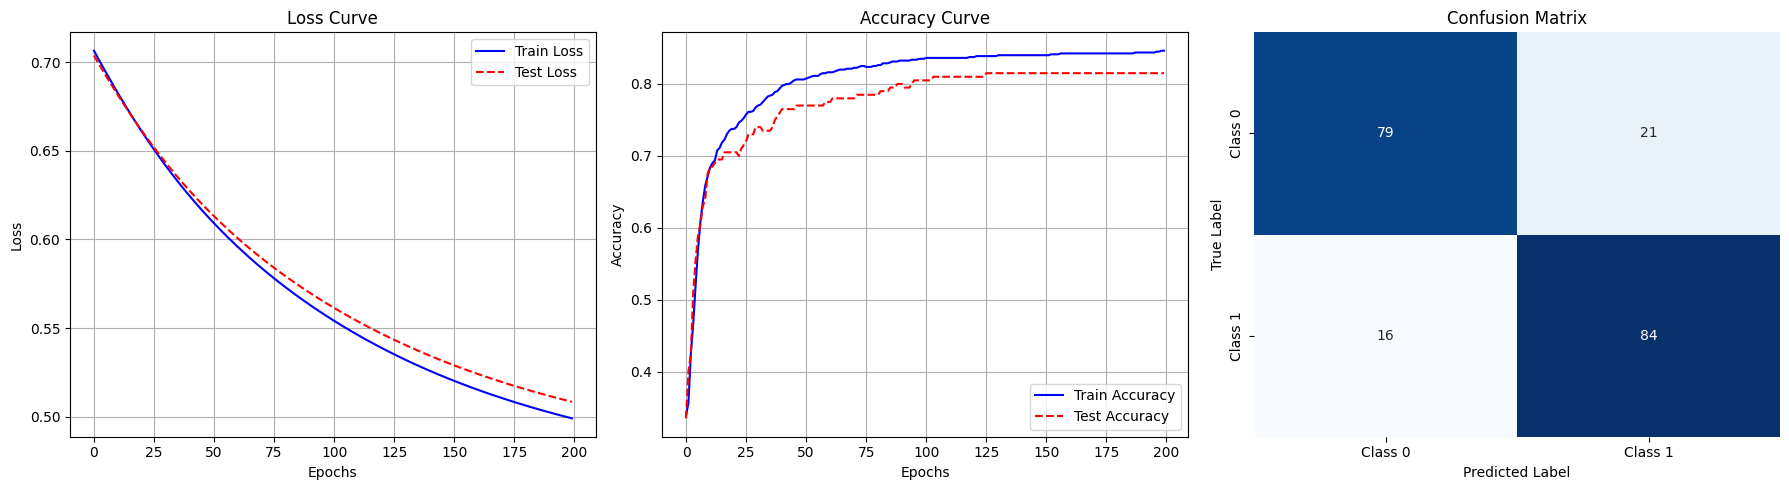

In [13]:
plt.figure(figsize=(18, 5))

# 1. Loss Graph
plt.subplot(1, 3, 1)
plt.plot(train_losses, label='Train Loss', color='blue')
plt.plot(test_losses, label='Test Loss', color='red', linestyle='--')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# 2. Accuracy Graph
plt.subplot(1, 3, 2)
plt.plot(train_accs, label='Train Accuracy', color='blue')
plt.plot(test_accs, label='Test Accuracy', color='red', linestyle='--')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# 3. Confusion Matrix
plt.subplot(1, 3, 3)
y_pred = predicted_test.numpy()
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.tight_layout()
plt.show()

In [14]:
import os

# Recreate the figure to save it directly to a file
fig = plt.figure(figsize=(18, 5))

# 1. Loss Graph
plt.subplot(1, 3, 1)
plt.plot(train_losses, label='Train Loss', color='blue')
plt.plot(test_losses, label='Test Loss', color='red', linestyle='--')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# 2. Accuracy Graph
plt.subplot(1, 3, 2)
plt.plot(train_accs, label='Train Accuracy', color='blue')
plt.plot(test_accs, label='Test Accuracy', color='red', linestyle='--')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# 3. Confusion Matrix
plt.subplot(1, 3, 3)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.tight_layout()

# Save the plot to the local workspace
output_filename = 'metrics_visualization.png'
plt.savefig(output_filename, dpi=300)
plt.close(fig)

print(f"Graphs successfully saved as '{os.path.abspath(output_filename)}'. You can now find and download it from the files pane on the left!")

Graphs successfully saved as '/content/metrics_visualization.png'. You can now find and download it from the files pane on the left!


### 5. Numerical Metrics Evaluation
We calculate detailed metrics (Precision, Recall, F1-Score, and Accuracy) and save them to a text file.

In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate metrics using numpy arrays
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='binary')
recall = recall_score(y_test, y_pred, average='binary')
f1 = f1_score(y_test, y_pred, average='binary')

metrics_text = f"""===============================
      CLASSIFICATION METRICS
===============================
Accuracy:  {accuracy:.4f}
Precision: {precision:.4f}
Recall:    {recall:.4f}
F1-Score:  {f1:.4f}
===============================
"""

print(metrics_text)

# Save metrics to a file for downloading
metrics_filename = 'metrics_summary.txt'
with open(metrics_filename, 'w') as f:
    f.write(metrics_text)

print(f"Metrics summary successfully saved as '{os.path.abspath(metrics_filename)}'. You can find and download it from the files pane on the left!")

      CLASSIFICATION METRICS
Accuracy:  0.8150
Precision: 0.8000
Recall:    0.8400
F1-Score:  0.8195

Metrics summary successfully saved as '/content/metrics_summary.txt'. You can find and download it from the files pane on the left!
